In [ ]:
# Imagine a feature is super strong and over-dominates the model.
#     In linear regression, the weight becomes huge.
#     In ridge regression, the model says: "No, I will shrink all weights to avoid over-reliance on any feature."
# Thus, Ridge controls model complexity.

# Minimize SSE + L2 penalty

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
import numpy as np

# Generate a small dataset
np.random.seed(0)
X = np.random.randn(100, 5)  # 5 features
y = 3*X[:,0] + 2*X[:,1] + np.random.randn(100)  # only 2 features matter

# Train/test split
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)

# Linear Regression
lr = LinearRegression()
lr.fit(X_train, y_train)
y_pred_lr = lr.predict(X_test)

# Ridge Regression
ridge = Ridge(alpha=1.0)
ridge.fit(X_train, y_train)
y_pred_ridge = ridge.predict(X_test)

print("Linear Regression RMSE:", mean_squared_error(y_test, y_pred_lr, squared=False))
print("Ridge Regression RMSE:", mean_squared_error(y_test, y_pred_ridge, squared=False))

print("Linear Regression Coefficients:", lr.coef_)
print("Ridge Regression Coefficients:", ridge.coef_)


Linear Regression RMSE: 0.9648757173971281
Ridge Regression RMSE: 0.964035050873854
Linear Regression Coefficients: [ 3.0380825   2.07383443  0.21175442  0.0157225  -0.17074495]
Ridge Regression Coefficients: [ 2.99360102  2.04118691  0.19826755  0.01485474 -0.17059163]


/home/monsley/anaconda3/envs/E3/lib/python3.12/site-packages/sklearn/metrics/_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(
/home/monsley/anaconda3/envs/E3/lib/python3.12/site-packages/sklearn/metrics/_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(


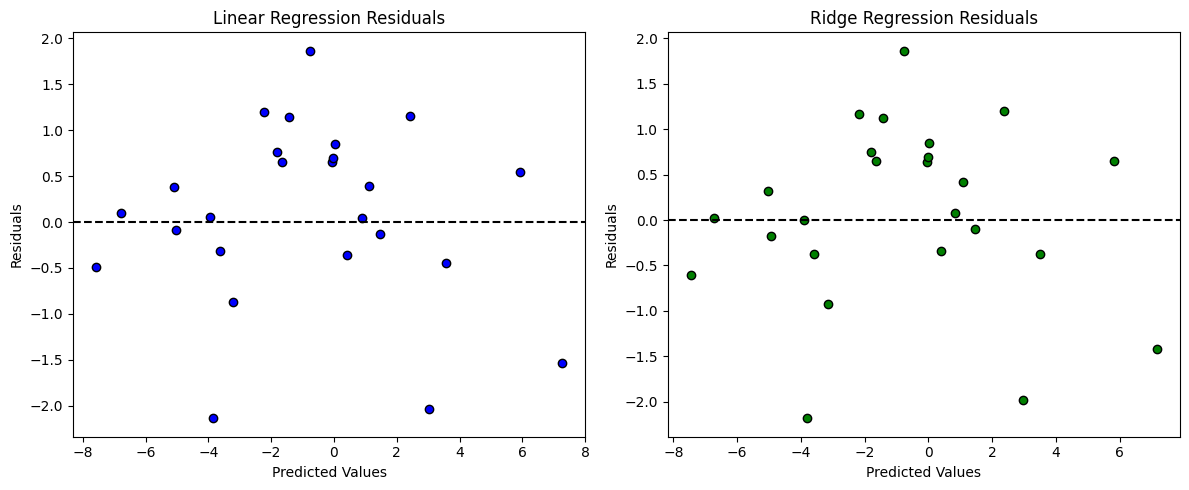

In [ ]:
import matplotlib.pyplot as plt

# Calculate residuals
residuals_lr = y_test - y_pred_lr
residuals_ridge = y_test - y_pred_ridge

# Plot
plt.figure(figsize=(12, 5))

# Linear Regression residuals
plt.subplot(1, 2, 1)
plt.scatter(y_pred_lr, residuals_lr, color='blue', edgecolor='k')
plt.axhline(y=0, color='black', linestyle='--')
plt.title('Linear Regression Residuals')
plt.xlabel('Predicted Values')
plt.ylabel('Residuals')

# Ridge Regression residuals
plt.subplot(1, 2, 2)
plt.scatter(y_pred_ridge, residuals_ridge, color='green', edgecolor='k')
plt.axhline(y=0, color='black', linestyle='--')
plt.title('Ridge Regression Residuals')
plt.xlabel('Predicted Values')
plt.ylabel('Residuals')

plt.tight_layout()
plt.show()


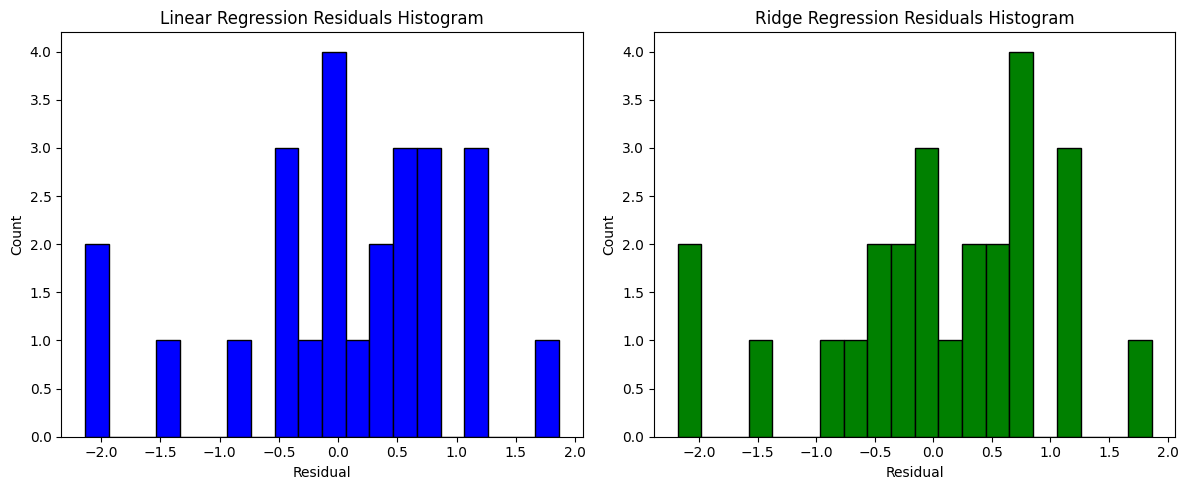

In [ ]:
plt.figure(figsize=(12, 5))

# Histogram of residuals
plt.subplot(1, 2, 1)
plt.hist(residuals_lr, bins=20, color='blue', edgecolor='k')
plt.title('Linear Regression Residuals Histogram')
plt.xlabel('Residual')
plt.ylabel('Count')

plt.subplot(1, 2, 2)
plt.hist(residuals_ridge, bins=20, color='green', edgecolor='k')
plt.title('Ridge Regression Residuals Histogram')
plt.xlabel('Residual')
plt.ylabel('Count')

plt.tight_layout()
plt.show()


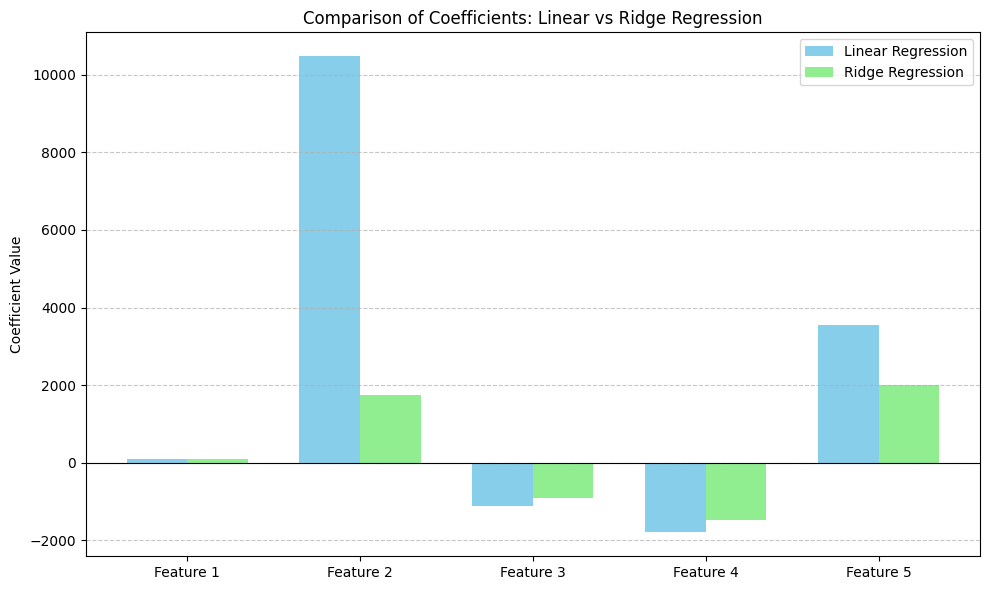

In [ ]:
import numpy as np
import matplotlib.pyplot as plt


# Get coefficients
coefficients_lr = lr.coef_
coefficients_ridge = ridge.coef_

# Feature names (optional, if you know them)
feature_names = [f'Feature {i+1}' for i in range(len(coefficients_lr))]

x = np.arange(len(coefficients_lr))  # the label locations
width = 0.35  # width of the bars

fig, ax = plt.subplots(figsize=(10,6))
rects1 = ax.bar(x - width/2, coefficients_lr, width, label='Linear Regression', color='skyblue')
rects2 = ax.bar(x + width/2, coefficients_ridge, width, label='Ridge Regression', color='lightgreen')

# Add labels, title and custom x-axis tick labels, etc.
ax.set_ylabel('Coefficient Value')
ax.set_title('Comparison of Coefficients: Linear vs Ridge Regression')
ax.set_xticks(x)
ax.set_xticklabels(feature_names)
ax.legend()

plt.axhline(0, color='black', linewidth=0.8)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


# a plot to show how coefficients "shrink" as alpha increases

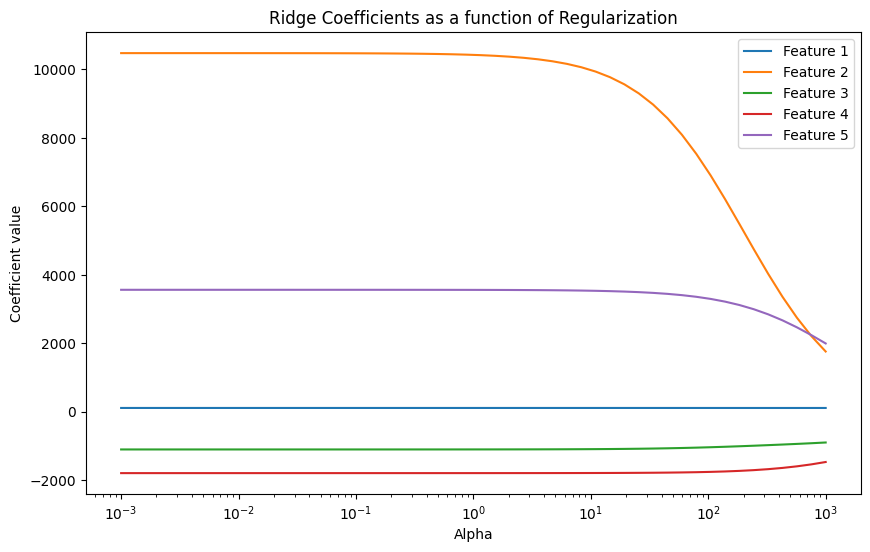

In [ ]:
# Varying alpha and plotting coefficient shrinkage
alphas = np.logspace(-3, 3, 50)
coefs = []

for a in alphas:
    ridge = Ridge(alpha=a)
    ridge.fit(X_train, y_train)
    coefs.append(ridge.coef_)

coefs = np.array(coefs)

plt.figure(figsize=(10,6))
for i in range(coefs.shape[1]):
    plt.plot(alphas, coefs[:, i], label=f'Feature {i+1}')
plt.xscale('log')
plt.xlabel('Alpha')
plt.ylabel('Coefficient value')
plt.title('Ridge Coefficients as a function of Regularization')
plt.legend()
plt.show()


[1.e-06 1.e-05 1.e-04 1.e-03 1.e-02 1.e-01 1.e+00 1.e+01 1.e+02 1.e+03
 1.e+04 1.e+05 1.e+06]
Best Alpha selected by RidgeCV: 0.1
Ridge Regression RMSE with Best Alpha: 0.9646407205173799


/home/monsley/anaconda3/envs/E3/lib/python3.12/site-packages/sklearn/linear_model/_ridge.py:2341: FutureWarning: 'store_cv_values' is deprecated in version 1.5 and will be removed in 1.7. Use 'store_cv_results' instead.
  warnings.warn(
/home/monsley/anaconda3/envs/E3/lib/python3.12/site-packages/sklearn/metrics/_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(
/home/monsley/anaconda3/envs/E3/lib/python3.12/site-packages/sklearn/utils/deprecation.py:102: FutureWarning: Attribute `cv_values_` is deprecated in version 1.5 and will be removed in 1.7. Use `cv_results_` instead.
  warnings.warn(msg, category=FutureWarning)


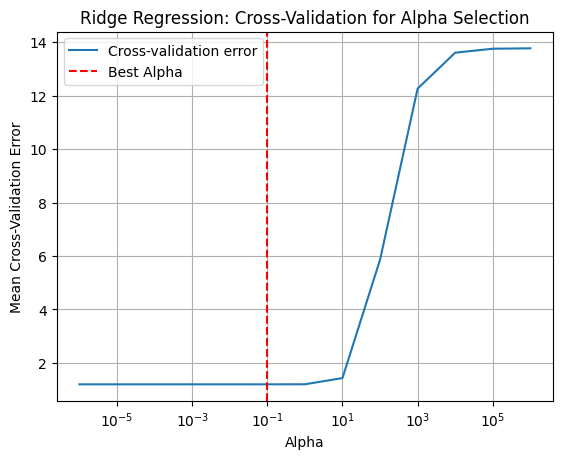

Ridge Regression Coefficients with Best Alpha: [ 3.03357194  2.07052192  0.21037507  0.01563387 -0.1707324 ]


In [ ]:
# so how do we select alpha values?????

from sklearn.linear_model import RidgeCV
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
import numpy as np
import matplotlib.pyplot as plt

# Generate a small dataset (as in your example)
np.random.seed(0)
X = np.random.randn(100, 5)  # 5 features
y = 3*X[:,0] + 2*X[:,1] + np.random.randn(100)  # only 2 features matter

# Train/test split
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)

# RidgeCV automatically selects the best alpha using cross-validation
alphas = np.logspace(-6, 6, 13)  # Alpha values in a logarithmic scale
ridge_cv = RidgeCV(alphas=alphas, store_cv_values=True)

# Fit RidgeCV
ridge_cv.fit(X_train, y_train)

# Get the best alpha
best_alpha = ridge_cv.alpha_
print("Best Alpha selected by RidgeCV:", best_alpha)

# Predict using the Ridge model with the best alpha
y_pred_ridge_cv = ridge_cv.predict(X_test)

# Calculate and print RMSE
rmse_ridge_cv = mean_squared_error(y_test, y_pred_ridge_cv, squared=False)
print("Ridge Regression RMSE with Best Alpha:", rmse_ridge_cv)

# Plot the cross-validation results for different alphas
plt.plot(alphas, ridge_cv.cv_values_.mean(axis=0), label="Cross-validation error")
plt.axvline(x=best_alpha, color='red', linestyle='--', label="Best Alpha")
plt.xscale('log')
plt.xlabel('Alpha')
plt.ylabel('Mean Cross-Validation Error')
plt.title('Ridge Regression: Cross-Validation for Alpha Selection')
plt.legend()
plt.grid(True)
plt.show()

# Coefficients of the Ridge regression
print("Ridge Regression Coefficients with Best Alpha:", ridge_cv.coef_)


# Lasso
Minimize SSE + L1 penalty

Lasso Regression (Least Absolute Shrinkage and Selection Operator) adds L1 regularization, which forces some coefficients to exactly zero, effectively performing feature selection.


In Lasso Regression, the regularization term automatically performs this feature selection by shrinking some coefficients to zero. Features corresponding to these coefficients are dropped from the model.

Thus, Lasso can be thought of as a built-in feature selection method because it:
    Reduces the number of features used in the model.
    Simplifies the model by focusing only on the features that matter the most.

Linear Regression Coefficients: [30971.07971791 11884.73172451 -9803.2417158  -9756.88144522
 10127.08482287]
Lasso Regression Coefficients: [30971.00589119 11884.63678792 -9803.13731205 -9756.79501985
 10126.97709189]


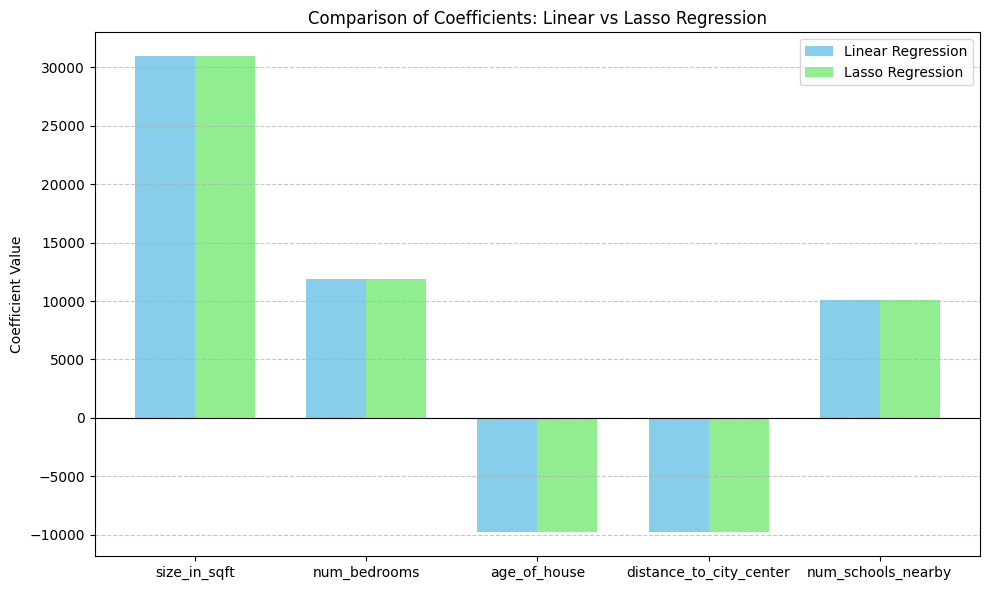

In [ ]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression, Lasso
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

# 1. Generate synthetic data
np.random.seed(42)
n_samples = 200

# Create features
X1 = np.random.normal(1500, 300, n_samples)  # Size in sqft
X2 = np.random.randint(1, 5, n_samples)     # Number of bedrooms
X3 = np.random.randint(0, 30, n_samples)    # Age of house
X4 = np.random.normal(10, 5, n_samples)    # Distance to city center
X5 = np.random.randint(0, 10, n_samples)   # Number of schools nearby

# House price with noise
y = (100*X1 + 5000*X2 - 1000*X3 - 2000*X4 + 3000*X5 + np.random.normal(0, 50000, n_samples))

# Create DataFrame
data = pd.DataFrame({
    'size_in_sqft': X1,
    'num_bedrooms': X2,
    'age_of_house': X3,
    'distance_to_city_center': X4,
    'num_schools_nearby': X5,
    'house_price': y
})

# Split data
X = data.drop('house_price', axis=1)
y = data['house_price']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Standardize the data
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Fit models
# Simple Linear Regression
lr = LinearRegression()
lr.fit(X_train_scaled, y_train)

# Lasso Regression with a larger alpha (stronger regularization)
lasso = Lasso(alpha=0.1)  # Stronger regularization
lasso.fit(X_train_scaled, y_train)

# 5. Compare Coefficients
print("Linear Regression Coefficients:", lr.coef_)
print("Lasso Regression Coefficients:", lasso.coef_)

# Plot the coefficients side by side
coefficients_lr = lr.coef_
coefficients_lasso = lasso.coef_

feature_names = X.columns

x = np.arange(len(coefficients_lr))  # Feature positions
width = 0.35  # Width of bars

fig, ax = plt.subplots(figsize=(10,6))
rects1 = ax.bar(x - width/2, coefficients_lr, width, label='Linear Regression', color='skyblue')
rects2 = ax.bar(x + width/2, coefficients_lasso, width, label='Lasso Regression', color='lightgreen')

# Add labels and titles
ax.set_ylabel('Coefficient Value')
ax.set_title('Comparison of Coefficients: Linear vs Lasso Regression')
ax.set_xticks(x)
ax.set_xticklabels(feature_names)
ax.legend()

plt.axhline(0, color='black', linewidth=0.8)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


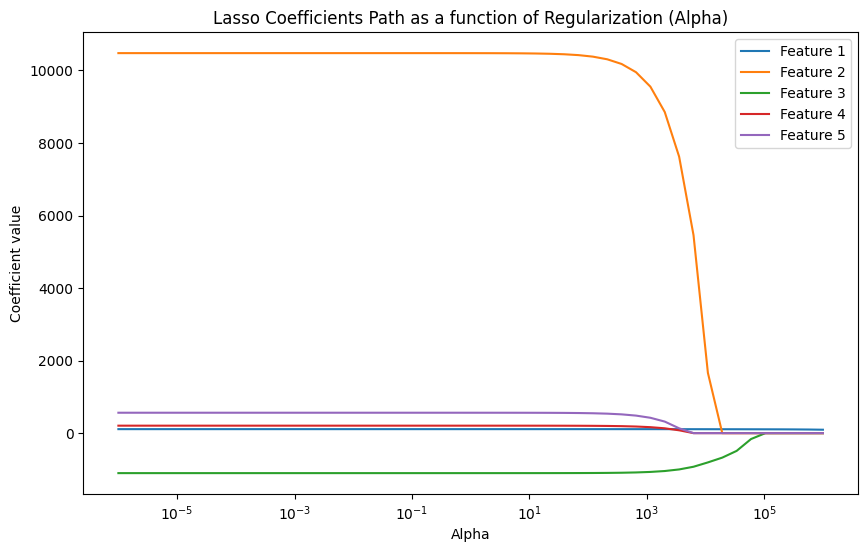

In [ ]:
# Varying alpha to observe coefficient shrinkage
# a plot to show how coefficients "shrink" as alpha increases

alphas = np.logspace(-6, 6, 50)
coefs = []

for a in alphas:
    lasso = Lasso(alpha=a)
    lasso.fit(X_train, y_train)
    coefs.append(lasso.coef_)

coefs = np.array(coefs)

# Plot
plt.figure(figsize=(10, 6))
for i in range(coefs.shape[1]):
    plt.plot(alphas, coefs[:, i], label=f'Feature {i+1}')
plt.xscale('log')
plt.xlabel('Alpha')
plt.ylabel('Coefficient value')
plt.title('Lasso Coefficients Path as a function of Regularization (Alpha)')
plt.legend()
plt.show()


Lasso Coefficients: [29718.17254937 10707.55297496 -8464.12321502     0.
   608.95829721]

Features with non-zero coefficients (selected by Lasso):
Index(['size_in_sqft', 'num_bedrooms', 'age_of_house', 'num_schools_nearby'], dtype='object')

Features with zero coefficients (removed by Lasso):
Index(['distance_to_city_center'], dtype='object')


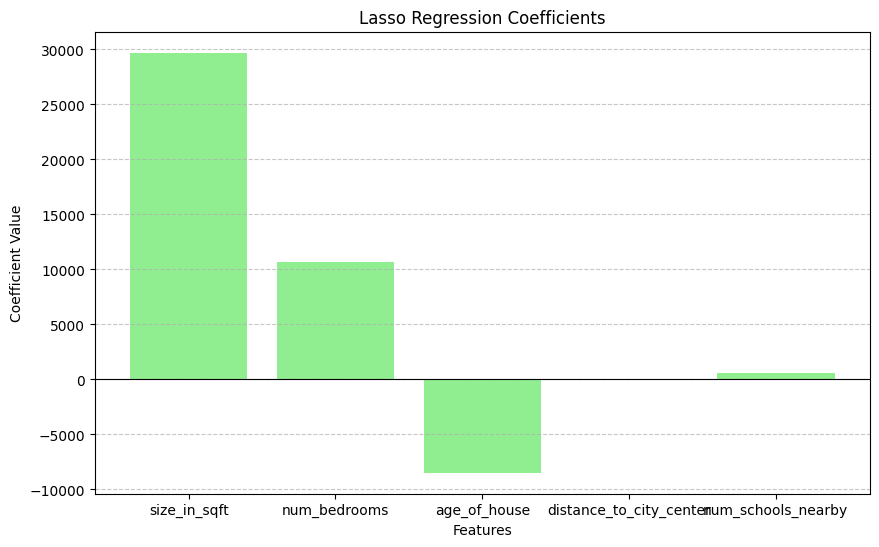

In [ ]:
import numpy as np
import pandas as pd
from sklearn.linear_model import Lasso
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

# Step 1: Create synthetic data with some irrelevant features
np.random.seed(42)
n_samples = 200

# Features
X1 = np.random.normal(1500, 300, n_samples)  # Size in sqft (relevant feature)
X2 = np.random.randint(1, 5, n_samples)     # Number of bedrooms (relevant feature)
X3 = np.random.randint(0, 30, n_samples)    # Age of house (relevant feature)
X4 = np.random.normal(10, 5, n_samples)     # Distance to city center (irrelevant)
X5 = np.random.randint(0, 10, n_samples)    # Number of schools nearby (irrelevant)

# House price with noise (target variable)
y = (100*X1 + 5000*X2 - 1000*X3 + np.random.normal(0, 50000, n_samples))

# Step 2: Create a DataFrame
data = pd.DataFrame({
    'size_in_sqft': X1,
    'num_bedrooms': X2,
    'age_of_house': X3,
    'distance_to_city_center': X4,
    'num_schools_nearby': X5,
    'house_price': y
})

# Step 3: Split data into training and test sets
X = data.drop('house_price', axis=1)
y = data['house_price']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Step 4: Standardize the data
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Step 5: Fit Lasso Regression with a larger alpha for stronger regularization
lasso = Lasso(alpha=1000.0)
lasso.fit(X_train_scaled, y_train)

# Step 6: View the coefficients after fitting the model
print("Lasso Coefficients:", lasso.coef_)

# Step 7: Identify which features have non-zero coefficients
non_zero_features = X.columns[lasso.coef_ != 0]
zero_features = X.columns[lasso.coef_ == 0]

print("\nFeatures with non-zero coefficients (selected by Lasso):")
print(non_zero_features)

print("\nFeatures with zero coefficients (removed by Lasso):")
print(zero_features)

# Step 8: Visualize the coefficients
coefficients = lasso.coef_
feature_names = X.columns

# Plot the coefficients
plt.figure(figsize=(10, 6))
plt.bar(feature_names, coefficients, color='lightgreen')
plt.axhline(0, color='black', linewidth=0.8)
plt.title('Lasso Regression Coefficients')
plt.ylabel('Coefficient Value')
plt.xlabel('Features')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()


Optimal alpha selected by cross-validation: 2273.320150356578


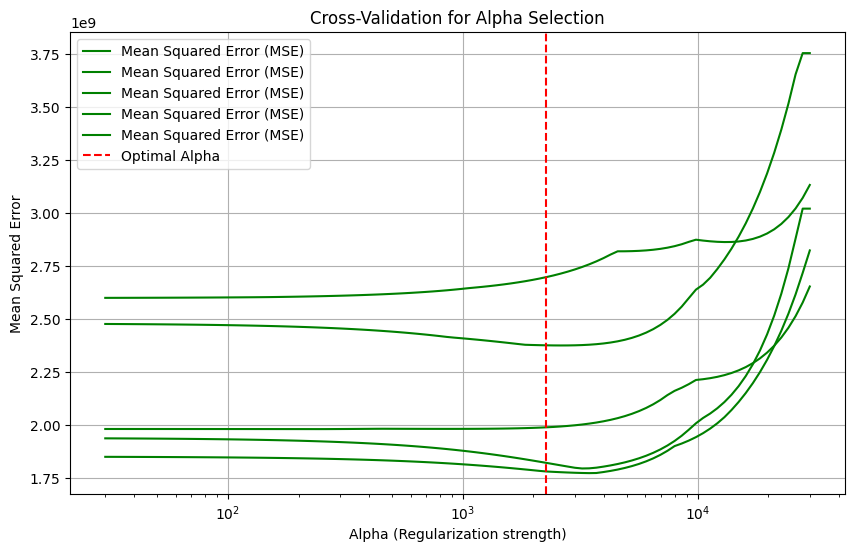

In [ ]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LassoCV
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

# Create synthetic data (as before)
np.random.seed(42)
n_samples = 200

# Features
X1 = np.random.normal(1500, 300, n_samples)  # Size in sqft (relevant feature)
X2 = np.random.randint(1, 5, n_samples)     # Number of bedrooms (relevant feature)
X3 = np.random.randint(0, 30, n_samples)    # Age of house (relevant feature)
X4 = np.random.normal(10, 5, n_samples)     # Distance to city center (irrelevant)
X5 = np.random.randint(0, 10, n_samples)    # Number of schools nearby (irrelevant)

# House price with noise (target variable)
y = (100*X1 + 5000*X2 - 1000*X3 + np.random.normal(0, 50000, n_samples))

# Create a DataFrame
data = pd.DataFrame({
    'size_in_sqft': X1,
    'num_bedrooms': X2,
    'age_of_house': X3,
    'distance_to_city_center': X4,
    'num_schools_nearby': X5,
    'house_price': y
})

# Split data into training and test sets
X = data.drop('house_price', axis=1)
y = data['house_price']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Standardize the data
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# LassoCV for automatic alpha selection
lasso_cv = LassoCV(cv=5, random_state=42, max_iter=10000)  # 5-fold cross-validation
lasso_cv.fit(X_train_scaled, y_train)

# Check the optimal alpha found by cross-validation
best_alpha = lasso_cv.alpha_
print("Optimal alpha selected by cross-validation:", best_alpha)

# Step 3: Plot the Mean Squared Error (MSE) for different alphas
alphas = lasso_cv.alphas_  # List of alphas tested during cross-validation
mse_values = lasso_cv.mse_path_  # MSE for each alpha

plt.figure(figsize=(10, 6))
plt.plot(alphas, mse_values, label="Mean Squared Error (MSE)", color="green")
plt.axvline(x=best_alpha, color='red', linestyle='--', label="Optimal Alpha")
plt.xscale('log')
plt.xlabel('Alpha (Regularization strength)')
plt.ylabel('Mean Squared Error')
plt.title('Cross-Validation for Alpha Selection')
plt.legend()
plt.grid(True)
plt.show()


In [ ]:
1 -